# quiz 1

旅遊行程助手：本機 Qwen3 工具呼叫 × Tavily basic search。下方既有輸出是切換前的 Groq 紀錄，重跑後才會更新成本機結果。

基礎展示包含五個工具的直接呼叫，以及兩個任務各兩種問法。評分截圖可擷取五個工具各自的回傳結果。進階展示包含六組比較及一組 ReAct 流程。

## 設定與匯入
VS Code 右上選取 **MMIP (Python 3.13.13)** kernel。依 [README](README.md) 安裝 Transformers，首次使用會從 Hugging Face 下載權重，在根目錄 `.env` 設定 `TAVILY_API_KEY`。這格只匯入工具和顯示模型設定。

In [34]:
import sys, json
from pathlib import Path
print('sys.executable =', sys.executable)
assert (Path.cwd()/'other_code'/'quiz1.py').exists(), '請從專案根目錄開啟 Notebook'
from other_code.quiz1 import DEFAULT_MODEL, COMPARISON_MODELS, TravelChat, TravelTools, ServiceError, show, compare
MODEL = DEFAULT_MODEL  # Qwen/Qwen3-1.7B
print('Qwen 模型:', MODEL, '；進階比較:', ', '.join(COMPARISON_MODELS))
MAX_ROUNDS = 12
def new_chat(prompt=''): return TravelChat(model=MODEL, prompt=prompt, max_rounds=MAX_ROUNDS)
def safe_tool(fn, *args, **kwargs):
    try:
        result = fn(*args, **kwargs)
        print(json.dumps(result, ensure_ascii=False, indent=2))
        return result
    except (ServiceError, ValueError) as exc:
        print(str(exc))
        return None

sys.executable = /root/venvs/MMIP/bin/python
Qwen 模型: Qwen/Qwen3-1.7B ；進階比較: Qwen/Qwen3-1.7B, Qwen/Qwen3-0.6B


## 逐一呼叫工具 1：search_places
搜尋京都站甜點和購物，顯示候選 ID、摘要與來源。

In [35]:
direct = TravelTools()
searched = safe_tool(direct.search_places, '京都站', '甜點 購物')

{
  "places": [
    {
      "id": "p1",
      "name": "2026 京都站及周邊必買推薦| Trip Moments",
      "summary": "住宿 機票 火車票 租車及機場接送 租車 機場接送 門票/體驗 門票/體驗 eSIM 機＋酒 私人包團 跟團遊 郵輪 Trip.Planner 旅遊靈感 旅遊攻略 Trip.Best 旅遊地圖 Trip.com 獎勵計畫 優惠 App 客服支援 尋找訂單 首頁 Trip Moments 貼文 日本 京都 京都站及周邊 京都站及周邊 – 必買旅遊攻略及討論 Trip Moments 貼文摘要 由 AI 產生 主題體驗：不少旅客提到京都站就是採買京都伴手禮的一級戰區，抹茶甜點、和菓子、京漬物與小巧工藝在「みやこみち」與「京名菓・名菜處 亰」最集中。選品帶有明顯京都限定感，送禮自用皆體面好帶。 省時動線：車站直結的「おもてなし小路」與站內1–2樓土產區，適合在轉乘空檔快速掃貨，連檢票內也有販售駅弁與小點。對行程緊湊者，邊移動邊買最省時，不必為採購特地繞路。 周邊甜點補貨：不少人把甜點列入必買清單，站周邊的大型商場內有多家甜甜圈與洋菓子專門店，外帶方便也很適合當小禮。步行可達、選擇多元，價格帶彈性，整體CP值不錯。 顯示更多 京都塔，欣賞京都璀璨夜景的絕佳位置@京都塔 [...] 鬆軟入口🫶🏻 其他還有特別的世界甜甜圈 像是荷蘭很受歡迎的Oliebollen 讓人很感興趣，下次想再去挑戰♡ 然後因為沒遇到剛出爐的時間 所以沒買到，但店裡最推薦的 「焦糖×巧克力」系列 看起來也很好吃💗 可以",
      "url": "https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-2040169-store-993139",
      "opening_hours": "待確認"
    },
    {
      "id": "p2",
      "name": "京都車站購物攻略2026｜Porta、伊勢丹、伴手禮、藥妝與美食推薦 @來一球叭噗",
      "summary": "| 想買什麼 | 推薦地點 |\n---|\n| 服飾、雜貨、藥妝 | 

### 工具 2：filter_by_area
以來源文字篩京都站，顯示符合候選。不是實測距離。

In [36]:
areas = safe_tool(direct.filter_by_area, '京都站')
area_ids = [p['id'] for p in (areas or {}).get('places', [])]

{
  "places": [
    {
      "id": "p1",
      "name": "2026 京都站及周邊必買推薦| Trip Moments",
      "summary": "住宿 機票 火車票 租車及機場接送 租車 機場接送 門票/體驗 門票/體驗 eSIM 機＋酒 私人包團 跟團遊 郵輪 Trip.Planner 旅遊靈感 旅遊攻略 Trip.Best 旅遊地圖 Trip.com 獎勵計畫 優惠 App 客服支援 尋找訂單 首頁 Trip Moments 貼文 日本 京都 京都站及周邊 京都站及周邊 – 必買旅遊攻略及討論 Trip Moments 貼文摘要 由 AI 產生 主題體驗：不少旅客提到京都站就是採買京都伴手禮的一級戰區，抹茶甜點、和菓子、京漬物與小巧工藝在「みやこみち」與「京名菓・名菜處 亰」最集中。選品帶有明顯京都限定感，送禮自用皆體面好帶。 省時動線：車站直結的「おもてなし小路」與站內1–2樓土產區，適合在轉乘空檔快速掃貨，連檢票內也有販售駅弁與小點。對行程緊湊者，邊移動邊買最省時，不必為採購特地繞路。 周邊甜點補貨：不少人把甜點列入必買清單，站周邊的大型商場內有多家甜甜圈與洋菓子專門店，外帶方便也很適合當小禮。步行可達、選擇多元，價格帶彈性，整體CP值不錯。 顯示更多 京都塔，欣賞京都璀璨夜景的絕佳位置@京都塔 [...] 鬆軟入口🫶🏻 其他還有特別的世界甜甜圈 像是荷蘭很受歡迎的Oliebollen 讓人很感興趣，下次想再去挑戰♡ 然後因為沒遇到剛出爐的時間 所以沒買到，但店裡最推薦的 「焦糖×巧克力」系列 看起來也很好吃💗 可以",
      "url": "https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-2040169-store-993139",
      "opening_hours": "待確認"
    },
    {
      "id": "p2",
      "name": "京都車站購物攻略2026｜Porta、伊勢丹、伴手禮、藥妝與美食推薦 @來一球叭噗",
      "summary": "| 想買什麼 | 推薦地點 |\n---|\n| 服飾、雜貨、藥妝 | 

### 工具 3：filter_by_category
顯示甜點與購物的實際篩選結果。綜合介紹頁可能符合兩類。

In [37]:
desserts = safe_tool(direct.filter_by_category, '甜點', area_ids)
shopping = safe_tool(direct.filter_by_category, '購物', area_ids)

{
  "places": [
    {
      "id": "p1",
      "name": "2026 京都站及周邊必買推薦| Trip Moments",
      "summary": "住宿 機票 火車票 租車及機場接送 租車 機場接送 門票/體驗 門票/體驗 eSIM 機＋酒 私人包團 跟團遊 郵輪 Trip.Planner 旅遊靈感 旅遊攻略 Trip.Best 旅遊地圖 Trip.com 獎勵計畫 優惠 App 客服支援 尋找訂單 首頁 Trip Moments 貼文 日本 京都 京都站及周邊 京都站及周邊 – 必買旅遊攻略及討論 Trip Moments 貼文摘要 由 AI 產生 主題體驗：不少旅客提到京都站就是採買京都伴手禮的一級戰區，抹茶甜點、和菓子、京漬物與小巧工藝在「みやこみち」與「京名菓・名菜處 亰」最集中。選品帶有明顯京都限定感，送禮自用皆體面好帶。 省時動線：車站直結的「おもてなし小路」與站內1–2樓土產區，適合在轉乘空檔快速掃貨，連檢票內也有販售駅弁與小點。對行程緊湊者，邊移動邊買最省時，不必為採購特地繞路。 周邊甜點補貨：不少人把甜點列入必買清單，站周邊的大型商場內有多家甜甜圈與洋菓子專門店，外帶方便也很適合當小禮。步行可達、選擇多元，價格帶彈性，整體CP值不錯。 顯示更多 京都塔，欣賞京都璀璨夜景的絕佳位置@京都塔 [...] 鬆軟入口🫶🏻 其他還有特別的世界甜甜圈 像是荷蘭很受歡迎的Oliebollen 讓人很感興趣，下次想再去挑戰♡ 然後因為沒遇到剛出爐的時間 所以沒買到，但店裡最推薦的 「焦糖×巧克力」系列 看起來也很好吃💗 可以",
      "url": "https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-2040169-store-993139",
      "opening_hours": "待確認"
    },
    {
      "id": "p2",
      "name": "京都車站購物攻略2026｜Porta、伊勢丹、伴手禮、藥妝與美食推薦 @來一球叭噗",
      "summary": "| 想買什麼 | 推薦地點 |\n---|\n| 服飾、雜貨、藥妝 | 

### 工具 4：build_itinerary
依篩選候選排兩小時，顯示估計停留、交通、未排入原因及營業待確認。候選不足會明確跳過。

In [38]:
d = (desserts or {}).get('places', [])
s = (shopping or {}).get('places', [])
if d and s:
    second = next((p for p in s if p['id'] != d[0]['id']), s[0])
    safe_tool(direct.build_itinerary, 120, [dict(place_id=d[0]['id'], activity='甜點', stay_minutes=45), dict(place_id=second['id'], activity='購物', stay_minutes=55)])
else:
    print('真實搜尋未取得兩類候選，請檢查連線後重跑本節。')

{
  "stops": [
    {
      "place_id": "p1",
      "place": "2026 京都站及周邊必買推薦| Trip Moments",
      "activity": "甜點",
      "start": "14:00",
      "end": "14:45",
      "stay_minutes_estimate": 45,
      "travel_minutes_estimate": 0,
      "opening_hours": "待確認",
      "url": "https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-2040169-store-993139"
    },
    {
      "place_id": "p2",
      "place": "京都車站購物攻略2026｜Porta、伊勢丹、伴手禮、藥妝與美食推薦 @來一球叭噗",
      "activity": "購物",
      "start": "14:55",
      "end": "15:50",
      "stay_minutes_estimate": 55,
      "travel_minutes_estimate": 10,
      "opening_hours": "待確認",
      "url": "https://gototravel.tw/kyoto-shopping-spot"
    }
  ],
  "omitted": [],
  "available_minutes": 120,
  "used_minutes_estimate": 110,
  "remaining_minutes": 10,
  "notice": "停留與移動時間皆為估計；營業時間與距離待確認。若為綜合頁，出發前須選定單店。"
}


### 工具 5：export_itinerary
這格明確要求匯出示範行程，顯示 UTF-8 Markdown 路徑。資料夾自動建立，每次檔名不同；無行程會顯示原因。

In [39]:
direct_export = safe_tool(direct.export_itinerary)

{
  "path": "/root/MMIP/week12/result/quiz1/itinerary_20261125_175345_204386_8ff04b6f.md",
  "encoding": "UTF-8"
}


## 評分題 A1
建立全新 session 執行「幫我找京都站附近的甜點店，附上來源。」。這題另外提醒模型在回答前實際呼叫區域篩選工具。執行後可查看回答、來源和各輪工具紀錄。

In [40]:
chat_A1 = new_chat(prompt='這題必須實際呼叫 filter_by_area，傳入 area=京都站，並依它回傳的候選回答。搜尋結果提到京都站也必須執行區域篩選。')
result_A1 = chat_A1.send('幫我找京都站附近的甜點店，附上來源。')
show(result_A1)

目前尚未有使用者要求存檔行程，因此無法進行行程匯出。如需存檔，請明確告知。

### 來源
- <https://tw.wamazing.com/media/article/a-568>
- <https://hk.trip.com/moments/detail/kyoto-430-125991378>
- <https://osaka.letsgojp.com/archives/89603>
- <https://www.threads.com/@ritazac315/post/DV7nt66Etl9/%E4%BA%AC%E9%83%BD%E8%BB%8A%E7%AB%99%E9%99%84%E8%BF%91%E4%B9%9F%E6%98%AF%E4%B8%80%E9%96%93%E5%9B%9E%E8%A8%AA%E5%A4%9A%E6%AC%A1%E7%9A%84%E6%84%9B%E5%BA%97%E9%99%A4%E4%BA%86%E4%BA%AC%E9%83%BD%E5%BF%85%E5%82%99%E7%9A%84%E5%A5%BD%E6%8A%B9%E8%8C%B6%E6%8B%BF%E9%90%B5%E5%B7%B4%E6%96%AF%E5%85%8B%E8%9B%8B%E7%B3%95%E6%9B%B4%E6%98%AF%E8%AE%93%E4%BA%BA%E7%9C%BC%E7%9D%9B%E5%98%B4%E5%B7%B4%E4%B8%80%E4%BA%AE%E8%B3%AA%E5%9C%B0%E6%9F%94%E6%BB%91%E7%B4%B0%E7%B7%BB%E3%84%A7%E6%97%81%E7%9A%84%E6%B5%B7%E9%B9%BD%E6%B2%BE%E8%91%97%E5%90%83%E7%94%9C%E9%B9%B9%E6%96%BC%E8%88%8C%E9%96%93%E4%BA%A4%E9%8C%AF%E7%9C%9F%E6%98%AF%E5%A5%BD%E5%90%83%E6%AD%BB%E4%BA%86%E6%AF%8F%E5%A4%A9830%E9%96%8B%E9%96%80%E8%B5%B7%E5%8F%B8>
- <https://tw.savorjapan.com/contents/discover-oishii-japan/15-cafes-in-kyoto-where-to-find-the-most-delicious-desserts>

各輪實際工具、參數、回傳結果、工具耗時及模型耗時（秒）
[
  {
    "round": 1,
    "tool": "search_places",
    "arguments": {
      "area": "京都站",
      "activities": "甜點"
    },
    "result": {
      "places": [
        {
          "id": "p1",
          "name": "來一趟京都甜點之旅吧！精選必吃9間甜點店＆人氣伴手禮推薦3選 - 完美行旅遊情報（WAmazing Discover）",
          "summary": "草莓蛋糕\n\n位於京都知名觀光景點「六角堂」附近的草莓甜點專賣店「MAISON DE FROUGE」（メゾン・ド・フルージュ）想要將草莓的美味極大化，因應季節與氣候的變化，從日本各地的草莓中選用最適合的品種來製作成甜點，每天的草莓品種都略有不同，是一間可以數度造訪也不會膩的甜點店。從草莓蛋糕、草莓千層派、草莓塔、草莓布丁通通有，草莓控們快點把這間甜點店收藏起來吧！\n\nMAISON DE FROUGE 京都三條店（メゾン・ド・フルージュ 京都三条店）  \n地址：京都府京都市中京区東洞院通三条下ル三文字町201  \n交通方式：從京都市營地鐵「烏丸御池站」徒步約3分鐘  \n官網：\n\n## ⑧別忘了在京都車站品嚐抹茶甜點！「中村藤吉本店 京都站店」\n\n中村藤吉抹茶凍\n\nPR TIMES\n\n創業自1854年的日本茶專賣店「中村藤吉本店」源自於京都宇治，茶葉品質優良獲獎無數，邁入甜點界後更是成為人氣名店，在京都、大阪、東京銀座的分店總是大排長龍，抹茶聖代、抹茶凍都是熱門必點的品項！ [...] 想參加抹茶體驗的話，可以前往位於宇治的本店，如果想要進一步體驗在茶葉產地學習抹茶的相關知識，也可以報名參加其他位於京都的「沖泡抹茶」及「抹茶粉拉花藝術」體驗課程。\n\n中村藤吉本店 京都駅店  \n地址：京都府京都市下京区烏丸通塩小路下ル東塩小路町（JR京都伊勢丹百貨3F）  \n交通方式：從各線「京都站」徒步",
          "url": "https://tw.wamazing.com/media/article/a-

## 評分題 A2
建立全新 session 執行「我在京都車站周邊想吃點甜的，有哪些地方可以去？」。顯示最終回答、來源、各輪實際工具／參數／回傳／耗時，以及匯出路徑。

In [41]:
chat_A2 = new_chat()
result_A2 = chat_A2.send('我在京都車站周邊想吃點甜的，有哪些地方可以去？')
show(result_A2)

目前尚未有使用者要求存檔行程，因此無法進行行程匯出。如需存檔，請明確告知。

### 來源
- <https://tabelog.com/tw/kyoto/A2601/A260101/R3313/rstLst/sweets>
- <https://hk.trip.com/moments/detail/kyoto-430-125991378>
- <https://tw.wamazing.com/media/article/a-568>
- <https://www.threads.com/@ritazac315/post/DV7nt66Etl9/%E4%BA%AC%E9%83%BD%E8%BB%8A%E7%AB%99%E9%99%84%E8%BF%91%E4%B9%9F%E6%98%AF%E4%B8%80%E9%96%93%E5%9B%9E%E8%A8%AA%E5%A4%9A%E6%AC%A1%E7%9A%84%E6%84%9B%E5%BA%97%E9%99%A4%E4%BA%86%E4%BA%AC%E9%83%BD%E5%BF%85%E5%82%99%E7%9A%84%E5%A5%BD%E6%8A%B9%E8%8C%B6%E6%8B%BF%E9%90%B5%E5%B7%B4%E6%96%AF%E5%85%8B%E8%9B%8B%E7%B3%95%E6%9B%B4%E6%98%AF%E8%AE%93%E4%BA%BA%E7%9C%BC%E7%9D%9B%E5%98%B4%E5%B7%B4%E4%B8%80%E4%BA%AE%E8%B3%AA%E5%9C%B0%E6%9F%94%E6%BB%91%E7%B4%B0%E7%B7%BB%E3%84%A7%E6%97%81%E7%9A%84%E6%B5%B7%E9%B9%BD%E6%B2%BE%E8%91%97%E5%90%83%E7%94%9C%E9%B9%B9%E6%96%BC%E8%88%8C%E9%96%93%E4%BA%A4%E9%8C%AF%E7%9C%9F%E6%98%AF%E5%A5%BD%E5%90%83%E6%AD%BB%E4%BA%86%E6%AF%8F%E5%A4%A9830%E9%96%8B%E9%96%80%E8%B5%B7%E5%8F%B8>
- <https://travel.udn.com/travel/story/9652/9205287>

各輪實際工具、參數、回傳結果、工具耗時及模型耗時（秒）
[
  {
    "round": 1,
    "tool": "search_places",
    "arguments": {
      "area": "京都車站周邊",
      "activities": "甜"
    },
    "result": {
      "places": [
        {
          "id": "p1",
          "name": "推薦適合在京都車站甜食 | Tabelog",
          "summary": "網上預訂\n\n關閉\n\nTabelog 日式點心・日式甜點店 WEST \"百名店\" 2026入選店\n\n京都車站 48m / 日式甜點店, 日式點心\n\n- \\-\n\n<!--THE END-->\n\n- 可信用卡付款\n- 禁止吸煙\n\n京都車站 127m / 西式自助餐, 咖啡店, 蛋糕\n\n位於京都車站直通的飯店內餐廳，提供主廚創作的豐富菜單，任你吃到飽！\n\n- 可信用卡付款\n- 禁止吸煙\n- 有Wi-Fi\n- 歡迎兒童\n- 有兒童菜單\n- 提供清真選項\n\n網上預訂查看空位\n\n京都車站 144m / 日式點心\n\n- 可信用卡付款\n- 禁止吸煙\n- 歡迎兒童\n\n東福寺車站 443m / 咖啡店, 鬆餅, 甜食\n\n全天候可享受下午茶的公園內咖啡廳◆適合帶小孩◎不時有馬匹來訪可互動◎\n\n- 提供多語言菜單\n- 有多語言服務人員\n- 可信用卡付款\n- 禁止吸煙\n- 有Wi-Fi\n- 歡迎兒童\n- 有兒童菜單\n- 提供帶照片的菜單\n- 提供電子菜單\n\n五條車站 722m / 咖啡店, 甜食\n\n【距離京都車站步行12分鐘】在築130年的京町家中享受季節限定的行李箱下午茶\n\n- 星期四 [...] - 星期四\n\n<!--THE END-->\n\n- 提供多語言菜單\n- 分區吸煙\n- 有Wi-Fi\n- 歡迎兒童\n- 提供帶照片的菜單\n\n京都車站 273m / 咖啡店, 甜甜圈, 三明治\n\n【距離京都車站步行1分",
          "url": "https://tabelog.com/tw/kyoto

## 評分題 B1
建立全新 session 執行「我在京都站附近只有兩小時，想先吃甜點再逛街，幫我排行程並存成Markdown。」。顯示最終回答、來源、各輪實際工具／參數／回傳／耗時，以及匯出路徑。

In [42]:
chat_B1 = new_chat(prompt='使用工具回傳的候選地點完成任務；請分別確認京都站區域、甜點與購物候選。候選足夠時不要停在搜尋或篩選：務必實際呼叫 build_itinerary，以 120 分鐘依先甜點、再購物的順序排程；排程成功後務必實際呼叫 export_itinerary。最後回答必須附上 export_itinerary 工具回傳的 Markdown 檔案路徑。若候選不足或任何工具失敗，請明確說明實際原因，不可虛構結果。')
result_B1 = chat_B1.send('我在京都站附近只有兩小時，想先吃甜點再逛街，幫我排行程並存成Markdown。')
show(result_B1)

以下是根據您的需求排程的行程，已存檔為 Markdown 檔案：

```markdown
# 京都站甜點購物行程

## 14:00 - 14:30 京都車站購物攻略2026｜Porta、伊勢丹、伴手禮、藥妝與美食推薦 @來一球叭噗
- **活動**: 甜點
- **停留時間**: 30 分鐘
- **移動時間**: 0 分鐘
- **總時間**: 14:00 - 14:30

## 14:30 - 15:30 京都車站景點地圖2026：車站美食購物、周邊推薦景點、一日遊行程攻略 | 樂吃購！日本 關西版
- **活動**: 購物
- **停留時間**: 45 分鐘
- **移動時間**: 15 分鐘
- **總時間**: 14:30 - 15:30
```

**存檔路徑**: `/root/MMIP/week12/result/quiz1/itinerary_20261125_175430_207257_3913f8bf.md`

請注意，此行程為根據工具回傳的候選地點與活動順序排程，實際營業時間與距離可能有所變動，建議出發前確認。

### 來源
- <https://gototravel.tw/kyoto-shopping-spot>
- <https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-2040169-store-993139>
- <https://www.gltjp.com/zh-hant/article/item/20827>
- <https://wow-japan.com/shopping-kyoto-station-shopping-guide>
- <https://osaka.letsgojp.com/archives/89603>

各輪實際工具、參數、回傳結果、工具耗時及模型耗時（秒）
[
  {
    "round": 1,
    "tool": "search_places",
    "arguments": {
      "area": "京都站",
      "activities": "甜點,購物"
    },
    "result": {
      "places": [
        {
          "id": "p1",
          "name": "京都車站購物攻略2026｜Porta、伊勢丹、伴手禮、藥妝與美食推薦 @來一球叭噗",
          "summary": "| 想買什麼 | 推薦地點 |\n---|\n| 服飾、雜貨、藥妝 | 京都Porta |\n| 精品、化妝品、甜點 | JR京都伊勢丹 |\n| 動漫、平價服飾 | 京都AVANTI |\n| 超市、生活用品 | AEON MALL KYOTO |\n| 3C、家電、藥妝 | 京都Yodobashi |\n| 京都伴手禮 | 京小町、ASTY京都、伊勢丹B1 |\n| 拉麵 | 京都拉麵小路 |\n| 聚餐、美食街 | Porta dining、伊勢丹11F、京都塔SANDO |\n| 建議停留時間 | 簡單逛1～2小時；購物＋吃飯約3～4小時 |\n\n### 京都車站內逛街地點\n\n- 京都Porta地下街\n\n京都車站直接相連的大型地下街，適合逛服飾、雜貨、藥妝、咖啡甜點與餐廳，下雨天也很好安排。\n\n- JR京都伊勢丹\n\n京都車站代表性百貨公司，可以逛精品、服飾、化妝品，也很適合到地下食品樓購買甜點、熟食與京都伴手禮。\n\n### 京都車站外逛街地點\n\n- 京都AVANTI\n\n位在京都站八條口附近，主打流行服飾、動漫與平價購物，可以找到GU、唐吉訶德、藥妝與卡通周邊。 [...] ### おみやげ小路 京小町\n\nおみやげ小路 京小町位於京都車站 1 樓烏丸口一帶，是京都車站內很方便的伴手禮區，有京漬物西利、土井志ば漬本舗、福壽園、鼓月、辻利等伴手禮店\n\n- 適合買：京漬物、抹茶菓子、焙茶甜點、京都和菓子",
          "url": "https://gototravel.tw/kyoto-shopping-spot",


## 評分題 B2
建立全新 session 執行「幫我安排京都車站周邊的120分鐘行程，順序是甜點、購物，最後匯出成Markdown檔。」。顯示最終回答、來源、各輪實際工具／參數／回傳／耗時，以及匯出路徑。

In [43]:
chat_B2 = new_chat()
result_B2 = chat_B2.send('幫我安排京都車站周邊的120分鐘行程，順序是甜點、購物，最後匯出成Markdown檔。')
show(result_B2)

目前根據提供的資料，無法找到符合「京都車站周邊」且屬於「甜點、購物」類別的真實單店。建議您進一步確認來源網頁是否為單店頁，並確認營業資訊是否已更新。

如果您需要，我可以協助您尋找其他符合條件的活動或建議其他適合的地區。

### 來源
- <https://gototravel.tw/kyoto-shopping-spot>
- <https://wow-japan.com/shopping-kyoto-station-shopping-guide>
- <https://osaka.letsgojp.com/archives/89603>
- <https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-2040169-store-993139>
- <https://www.gltjp.com/zh-hant/article/item/20827>

各輪實際工具、參數、回傳結果、工具耗時及模型耗時（秒）
[
  {
    "round": 1,
    "tool": "search_places",
    "arguments": {
      "area": "京都車站周邊",
      "activities": "甜點、購物"
    },
    "result": {
      "places": [
        {
          "id": "p1",
          "name": "京都車站購物攻略2026｜Porta、伊勢丹、伴手禮、藥妝與美食推薦 @來一球叭噗",
          "summary": "| 想買什麼 | 推薦地點 |\n---|\n| 服飾、雜貨、藥妝 | 京都Porta |\n| 精品、化妝品、甜點 | JR京都伊勢丹 |\n| 動漫、平價服飾 | 京都AVANTI |\n| 超市、生活用品 | AEON MALL KYOTO |\n| 3C、家電、藥妝 | 京都Yodobashi |\n| 京都伴手禮 | 京小町、ASTY京都、伊勢丹B1 |\n| 拉麵 | 京都拉麵小路 |\n| 聚餐、美食街 | Porta dining、伊勢丹11F、京都塔SANDO |\n| 建議停留時間 | 簡單逛1～2小時；購物＋吃飯約3～4小時 |\n\n### 京都車站內逛街地點\n\n- 京都Porta地下街\n\n京都車站直接相連的大型地下街，適合逛服飾、雜貨、藥妝、咖啡甜點與餐廳，下雨天也很好安排。\n\n- JR京都伊勢丹\n\n京都車站代表性百貨公司，可以逛精品、服飾、化妝品，也很適合到地下食品樓購買甜點、熟食與京都伴手禮。\n\n### 京都車站外逛街地點\n\n- 京都AVANTI\n\n位在京都站八條口附近，主打流行服飾、動漫與平價購物，可以找到GU、唐吉訶德、藥妝與卡通周邊。 [...] ## 京都車站美食去哪裡吃？\n\n京都車站餐廳很多，如果不知道去哪裡吃，可以直接照需求選：\n\n| 想吃什麼 | 推薦地點 |\n---|\n| 快速吃飯 | Porta dining |\n| 拉麵 | 京都拉麵小路 |\n| 百貨餐廳",
          "url": "https://gototravel.tw/kyoto-shopping-

### 五工具覆蓋檢查
統計目前 kernel 裡四題的工具紀錄，列出成功呼叫、尚缺工具和還沒有結果的題目。

In [44]:
required = {'search_places','filter_by_area','filter_by_category','build_itinerary','export_itinerary'}
questions = ('A1', 'A2', 'B1', 'B2')
results = {question: globals().get(f'result_{question}') for question in questions}
missing = [question for question, result in results.items() if result is None]
if missing:
    print('目前 kernel 尚無結果:', '、'.join(missing))
actual = {
    entry['tool'] for result in results.values() if result is not None
    for entry in result['trace'] if not entry['result'].get('error')
}
print('成功呼叫:', sorted(required & actual))
print('尚缺:', sorted(required - actual))

成功呼叫: ['build_itinerary', 'export_itinerary', 'filter_by_area', 'filter_by_category', 'search_places']
尚缺: []


## 進階：兩個模型 × 三種提示技巧
只重跑比較時，先執行「設定與匯入」，再執行本格。已有本次 kernel 的工具展示搜尋結果就共用，否則為六組做一次 Tavily 搜尋。每組用新對話執行相同的 B1 任務，表格列出完成狀態、工具順序、呼叫次數、耗時與錯誤。

In [45]:
from IPython.display import display, Markdown
comparison_rows, comparison_runs = [], []
comparison_search = globals().get('searched')
if not comparison_search or not comparison_search.get('places'):
    comparison_search = safe_tool(TravelTools().search_places, '京都站', '甜點 購物')
snapshot = (comparison_search or {}).get('places', [])
if snapshot:
    comparison_rows, comparison_runs = compare(snapshot, '我在京都站附近只有兩小時，想先吃甜點再逛街，幫我排行程並存成Markdown。')
    header = '|模型|技巧|完成|工具順序|次數|秒數|錯誤|\n|---|---|---|---|---|---|---|\n'
    table = '\n'.join(f"|{r['model']}|{r['technique']}|{r['completed']}|{' → '.join(r['tool_order'])}|{r['calls']}|{r['seconds']}|{r['error'] or ''}|" for r in comparison_rows)
    display(Markdown(header + table))
else:
    print('缺少真實搜尋資料，六組尚未執行；修復 Tavily 後重跑。')

|模型|技巧|完成|工具順序|次數|秒數|錯誤|
|---|---|---|---|---|---|---|
|Qwen/Qwen3-1.7B|直接指令|False|search_places → filter_by_area → filter_by_category → filter_by_area → filter_by_category → build_itinerary → build_itinerary → export_itinerary|8|20.4||
|Qwen/Qwen3-1.7B|角色與輸出要求|False|search_places → filter_by_area → filter_by_category → filter_by_area → filter_by_category → build_itinerary → export_itinerary|7|26.876||
|Qwen/Qwen3-1.7B|單一示範案例|False|search_places → filter_by_area → filter_by_category → filter_by_category → build_itinerary → build_itinerary → export_itinerary|7|20.63||
|Qwen/Qwen3-0.6B|直接指令|False|search_places → filter_by_area → filter_by_category → build_itinerary → export_itinerary|5|17.163||
|Qwen/Qwen3-0.6B|角色與輸出要求|False|search_places → filter_by_area → filter_by_category → build_itinerary → export_itinerary|5|8.214||
|Qwen/Qwen3-0.6B|單一示範案例|False|search_places → filter_by_area → filter_by_category → build_itinerary → export_itinerary|5|7.765||

### 討論六組結果與解讀 ReAct
比較六組的工具與完成狀態。若受限流干擾，依實際完成的步驟解讀，耗時無法單獨代表模型或提示技巧的效果。下格優先選擇完成的組別；若全部未完成，選擇執行工具最多的一組，依序查看模型呼叫、工具回傳和下一個動作。

In [46]:
if globals().get('comparison_runs'):
    completed_count = sum(row['completed'] for row in comparison_rows)
    print(f'完成組數：{completed_count}/{len(comparison_rows)}')
    for row in comparison_rows:
        last_tool = row['tool_order'][-1] if row['tool_order'] else '尚未呼叫工具'
        print(f"{row['model']}／{row['technique']}：{row['calls']} 次工具呼叫，最後動作：{last_tool}")
    chosen = max(range(len(comparison_rows)),
                 key=lambda i: (comparison_rows[i]['completed'], comparison_rows[i]['calls']))
    print('選擇組別:', comparison_rows[chosen])
    meanings = dict(search_places='取得候選與來源',filter_by_area='確認區域證據',filter_by_category='確認活動類型',build_itinerary='按時間與順序排程',export_itinerary='保存最近行程')
    for entry in comparison_runs[chosen]['trace']:
        print(f"第 {entry['round']} 輪：{entry['tool']}，{meanings.get(entry['tool'], '服務錯誤')}")
        print(json.dumps(entry, ensure_ascii=False, indent=2))
    show(comparison_runs[chosen])
else:
    print('尚無實際比較紀錄。')

完成組數：0/6
Qwen/Qwen3-1.7B／直接指令：8 次工具呼叫，最後動作：export_itinerary
Qwen/Qwen3-1.7B／角色與輸出要求：7 次工具呼叫，最後動作：export_itinerary
Qwen/Qwen3-1.7B／單一示範案例：7 次工具呼叫，最後動作：export_itinerary
Qwen/Qwen3-0.6B／直接指令：5 次工具呼叫，最後動作：export_itinerary
Qwen/Qwen3-0.6B／角色與輸出要求：5 次工具呼叫，最後動作：export_itinerary
Qwen/Qwen3-0.6B／單一示範案例：5 次工具呼叫，最後動作：export_itinerary
選擇組別: {'model': 'Qwen/Qwen3-1.7B', 'technique': '直接指令', 'completed': False, 'tool_order': ['search_places', 'filter_by_area', 'filter_by_category', 'filter_by_area', 'filter_by_category', 'build_itinerary', 'build_itinerary', 'export_itinerary'], 'calls': 8, 'seconds': 20.4, 'error': None}
第 1 輪：search_places，取得候選與來源
{
  "round": 1,
  "tool": "search_places",
  "arguments": {
    "area": "京都站附近",
    "activities": "甜點,逛街"
  },
  "result": {
    "places": [
      {
        "id": "p1",
        "name": "2026 京都站及周邊必買推薦| Trip Moments",
        "summary": "住宿 機票 火車票 租車及機場接送 租車 機場接送 門票/體驗 門票/體驗 eSIM 機＋酒 私人包團 跟團遊 郵輪 Trip.Planner 旅遊靈感 旅遊攻略 Trip.Best 旅遊地圖 Trip.com 獎勵計畫 優惠 App

已成功匯出行程為Markdown格式，文件路徑為：

```
/root/MMIP/week12/result/quiz1/itinerary_20261125_175511_142303_9856772f.md
```

如需進一步協助，請隨時告知！

### 來源
- <https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-2040169-store-993139>
- <https://gototravel.tw/kyoto-shopping-spot>
- <https://www.gltjp.com/zh-hant/article/item/20827>
- <https://osaka.letsgojp.com/archives/89603>
- <https://wow-japan.com/shopping-kyoto-station-shopping-guide>

各輪實際工具、參數、回傳結果、工具耗時及模型耗時（秒）
[
  {
    "round": 1,
    "tool": "search_places",
    "arguments": {
      "area": "京都站附近",
      "activities": "甜點,逛街"
    },
    "result": {
      "places": [
        {
          "id": "p1",
          "name": "2026 京都站及周邊必買推薦| Trip Moments",
          "summary": "住宿 機票 火車票 租車及機場接送 租車 機場接送 門票/體驗 門票/體驗 eSIM 機＋酒 私人包團 跟團遊 郵輪 Trip.Planner 旅遊靈感 旅遊攻略 Trip.Best 旅遊地圖 Trip.com 獎勵計畫 優惠 App 客服支援 尋找訂單 首頁 Trip Moments 貼文 日本 京都 京都站及周邊 京都站及周邊 – 必買旅遊攻略及討論 Trip Moments 貼文摘要 由 AI 產生 主題體驗：不少旅客提到京都站就是採買京都伴手禮的一級戰區，抹茶甜點、和菓子、京漬物與小巧工藝在「みやこみち」與「京名菓・名菜處 亰」最集中。選品帶有明顯京都限定感，送禮自用皆體面好帶。 省時動線：車站直結的「おもてなし小路」與站內1–2樓土產區，適合在轉乘空檔快速掃貨，連檢票內也有販售駅弁與小點。對行程緊湊者，邊移動邊買最省時，不必為採購特地繞路。 周邊甜點補貨：不少人把甜點列入必買清單，站周邊的大型商場內有多家甜甜圈與洋菓子專門店，外帶方便也很適合當小禮。步行可達、選擇多元，價格帶彈性，整體CP值不錯。 顯示更多 京都塔，欣賞京都璀璨夜景的絕佳位置@京都塔 [...] 鬆軟入口🫶🏻 其他還有特別的世界甜甜圈 像是荷蘭很受歡迎的Oliebollen 讓人很感興趣，下次想再去挑戰♡ 然後因為沒遇到剛出爐的時間 所以沒買到，但店裡最推薦的 「焦糖×巧克力」系列 看起來也很好吃💗 可以",
          "url": "https://tw.trip.com/moments/theme/destination-kyoto-station-and-surrounding-areas-20

# quiz 2

多模態影像 Agent。以下依序展示直接函數呼叫，以及 8 工具版與 9 工具版的實際模型呼叫。

## 設定照片
設定資料夾與 8 工具版指定的兩個檔名。預設使用有重疊的合成測試圖，輸出會列出資料模式與檔名。正式照片放好後，將 `q2_use_synthetic` 改為 `False`。只跑 9 工具版時可將 `q2_names` 設為空 tuple `()`。

In [45]:
from pathlib import Path
from other_code.quiz2 import (
    ROOT as Q2_ROOT, MODEL_ID as Q2_MODEL_ID, CACHE_DIR as Q2_CACHE_DIR,
    ImageTools, ImageAgent, QwenVision, make_test_photos,
    show_call, show_preview, show_run,
)

q2_use_synthetic = False
q2_folder = "data/quiz2/set1"
q2_names = ("left.jpg", "right.jpg")
if q2_use_synthetic:
    q2_folder, q2_names = make_test_photos()

q2_paths = [(Path(q2_folder) / name).as_posix() for name in q2_names]
q2_direct = ImageTools()
q2_photos = [q2_direct.register_photo(path) for path in q2_paths]
print("合成測試資料" if q2_use_synthetic else "使用者提供的照片", q2_folder)
for q2_photo in q2_photos:
    print(q2_photo)

使用者提供的照片 data/quiz2/set1
{'image_id': 'photo:data/quiz2/set1/left.jpg', 'filename': 'left.jpg', 'path': 'data/quiz2/set1/left.jpg'}
{'image_id': 'photo:data/quiz2/set1/right.jpg', 'filename': 'right.jpg', 'path': 'data/quiz2/set1/right.jpg'}


## 直接呼叫 1：亮度校正
以第一張照片為亮度基準校正第二張。輸出包含實際參數、增益和亮度統計，並預覽基準照片及校正前後的照片。

{
  "tool": "match_exposure",
  "arguments": {
    "reference_id": "photo:data/quiz2/set1/left.jpg",
    "target_id": "photo:data/quiz2/set1/right.jpg"
  },
  "result": {
    "ok": true,
    "image_id": "exposure:6e5b96ca",
    "width": 1108,
    "height": 1477,
    "reference_id": "photo:data/quiz2/set1/left.jpg",
    "target_id": "photo:data/quiz2/set1/right.jpg",
    "gain": 0.983,
    "reference_mean": 150.15,
    "target_mean_before": 152.72,
    "target_mean_after": 149.69
  }
}
亮度基準 （原尺寸 1108 × 1477）


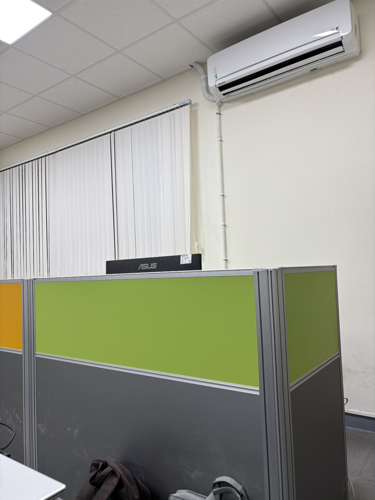

校正前 （原尺寸 1108 × 1477）


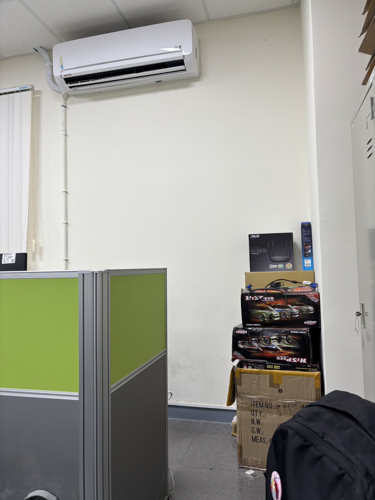

校正後 （原尺寸 1108 × 1477）


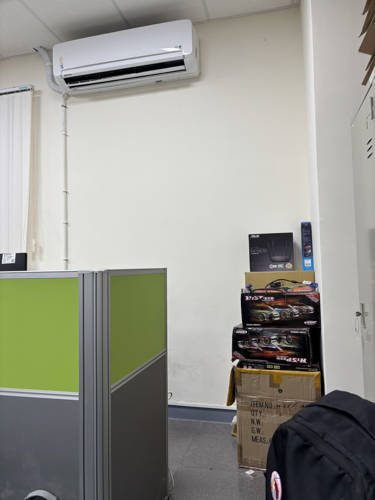

In [46]:
if len(q2_photos) != 2:
    raise ValueError('請在設定格指定兩張照片，再執行直接呼叫。')
q2_exposure_args = {
    "reference_id": q2_photos[0]["image_id"],
    "target_id": q2_photos[1]["image_id"],
}
q2_exposure = q2_direct.match_exposure(**q2_exposure_args)
show_call("match_exposure", q2_exposure_args, q2_exposure)
show_preview("亮度基準", q2_direct.image(q2_exposure_args["reference_id"]))
show_preview("校正前", q2_direct.image(q2_exposure_args["target_id"]))
if q2_exposure["ok"]:
    show_preview("校正後", q2_direct.image(q2_exposure["image_id"]))

## 直接呼叫 2：全景拼接
將基準照片與校正後的照片交給 OpenCV 拼接。輸出顯示實際圖片 ID、成功狀態與全景尺寸，成功時會預覽全景，失敗時會顯示原因。

{
  "tool": "stitch_images",
  "arguments": {
    "image_ids": [
      "photo:data/quiz2/set1/left.jpg",
      "exposure:6e5b96ca"
    ]
  },
  "result": {
    "ok": true,
    "image_id": "panorama:d931fb2d",
    "width": 1776,
    "height": 1369,
    "cache_status": "off",
    "opencv_executed": true,
    "source_ids": [
      "photo:data/quiz2/set1/left.jpg",
      "exposure:6e5b96ca"
    ],
    "opencv_status": 0
  }
}
全景預覽 （原尺寸 1776 × 1369）


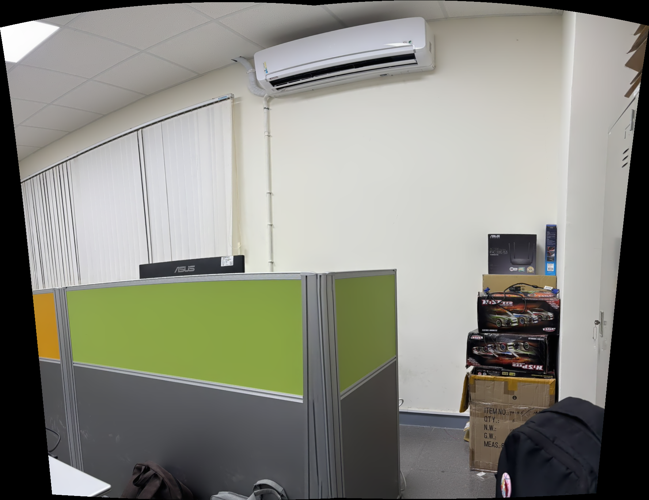

In [47]:
q2_second_id = q2_exposure["image_id"] if q2_exposure["ok"] else q2_photos[1]["image_id"]
q2_stitch_args = {"image_ids": [q2_photos[0]["image_id"], q2_second_id]}
q2_stitch = q2_direct.stitch_images(**q2_stitch_args)
show_call("stitch_images", q2_stitch_args, q2_stitch)
if q2_stitch["ok"]:
    show_preview("全景預覽", q2_direct.image(q2_stitch["image_id"]))

## 直接呼叫 3：PNG 存檔
將上一格成功產生的全景存入 `result/quiz2/`，輸出顯示實際參數和檔案路徑。上一格失敗時會說明無成品可存。

In [48]:
q2_saved = None
if q2_stitch["ok"]:
    q2_save_args = {"image_id": q2_stitch["image_id"], "filename": "direct_panorama.png"}
    q2_saved = q2_direct.save_image(**q2_save_args)
    show_call("save_image", q2_save_args, q2_saved)
else:
    print("沒有可存的全景圖。", q2_stitch["error"])

{
  "tool": "save_image",
  "arguments": {
    "image_id": "panorama:d931fb2d",
    "filename": "direct_panorama.png"
  },
  "result": {
    "ok": true,
    "image_id": "panorama:d931fb2d",
    "path": "result/quiz2/direct_panorama_07f0deb9.png",
    "width": 1776,
    "height": 1369
  }
}


## 載入視覺語言模型
在現有 kernel 的 CUDA GPU 上載入 Qwen2.5-VL-3B-Instruct，輸出模型名稱、裝置與專案內快取位置。首次會從官方模型庫下載。

In [49]:
if "q2_vision" not in globals() or not isinstance(q2_vision, QwenVision):
    q2_vision = QwenVision()
print(Q2_MODEL_ID, q2_vision.model.device)
print(f"模型與 processor 快取：{Q2_CACHE_DIR.relative_to(Q2_ROOT)}")

Qwen/Qwen2.5-VL-3B-Instruct cuda:0
模型與 processor 快取：.cache/quiz2/huggingface


## 8 工具版：指定兩張照片
將設定格指定的兩張照片與文字指令交給模型。輸出包含每輪實際送入的圖片 ID、工具參數與回傳，以及存檔路徑和成品預覽。

{
  "registered_tools": [
    "build_itinerary",
    "export_itinerary",
    "filter_by_area",
    "filter_by_category",
    "match_exposure",
    "save_image",
    "search_places",
    "stitch_images"
  ],
  "trace": [
    {
      "round": 1,
      "tool": "match_exposure",
      "arguments": {
        "reference_id": "photo:data/quiz2/set1/left.jpg",
        "target_id": "photo:data/quiz2/set1/right.jpg"
      },
      "result": {
        "ok": true,
        "image_id": "exposure:758b6684",
        "width": 1108,
        "height": 1477,
        "reference_id": "photo:data/quiz2/set1/left.jpg",
        "target_id": "photo:data/quiz2/set1/right.jpg",
        "gain": 0.983,
        "reference_mean": 150.15,
        "target_mean_before": 152.72,
        "target_mean_after": 149.69
      },
      "seconds": 0.061
    },
    {
      "round": 2,
      "tool": "stitch_images",
      "arguments": {
        "image_ids": [
          "photo:data/quiz2/set1/left.jpg",
          "exposure:758b6684

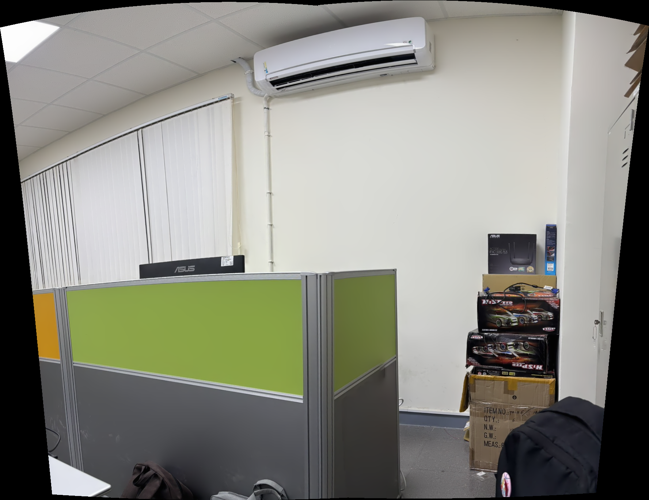

In [50]:
if len(q2_paths) != 2:
    raise ValueError('請在設定格指定兩張照片，再執行 8 工具版。')
q2_agent8 = ImageAgent(q2_vision)
q2_run8 = q2_agent8.run(
    "請看這兩張照片，判斷是否需要亮度校正，再把有重疊的畫面拼成全景。"
    "將全景存成 agent8_panorama.png，回答時附上工具回傳路徑。",
    photo_paths=q2_paths,
)
show_run(q2_run8)

## 9 工具版：只指定資料夾
模型先從指定資料夾取得照片，觀察工具回傳候選的實際影像後自己選圖。輸出包含取圖、後續工具的紀錄，以及存檔路徑和成品預覽。

{
  "registered_tools": [
    "build_itinerary",
    "export_itinerary",
    "filter_by_area",
    "filter_by_category",
    "get_local_photos",
    "match_exposure",
    "save_image",
    "search_places",
    "stitch_images"
  ],
  "trace": [
    {
      "round": 1,
      "tool": "get_local_photos",
      "arguments": {
        "folder": "data/quiz2/set1"
      },
      "result": {
        "ok": true,
        "folder": "data/quiz2/set1",
        "photos": [
          {
            "image_id": "photo:data/quiz2/set1/left.jpg",
            "filename": "left.jpg",
            "path": "data/quiz2/set1/left.jpg"
          },
          {
            "image_id": "photo:data/quiz2/set1/right.jpg",
            "filename": "right.jpg",
            "path": "data/quiz2/set1/right.jpg"
          }
        ],
        "unreadable": []
      },
      "seconds": 0.019
    },
    {
      "round": 2,
      "tool": "match_exposure",
      "arguments": {
        "reference_id": "photo:data/quiz2/set1/left

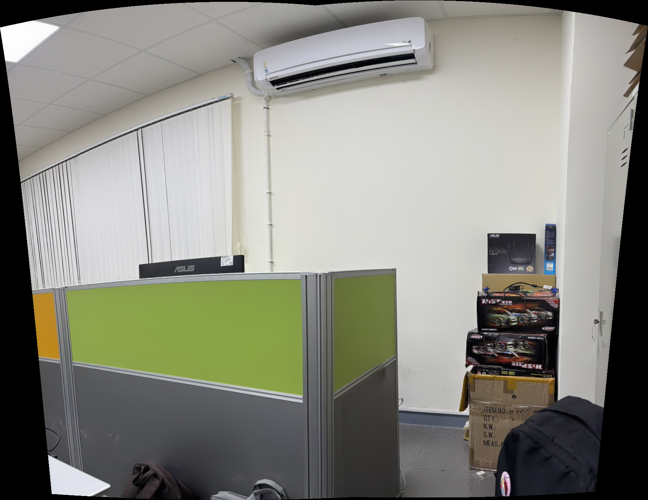

In [51]:
q2_agent9 = ImageAgent(q2_vision, with_local_photos=True)
q2_run9 = q2_agent9.run(
    "請從指定資料夾取得照片，觀察畫面後挑出重疊的照片。"
    "視需要校正亮度，拼成全景後存成 agent9_panorama.png，回答時附上工具回傳路徑。",
    folder=q2_folder,
)
show_run(q2_run9)

## 進階：拼接快取
準備固定的兩張影像和唯一的測試快取子目錄。預設使用合成測試圖，也可在 `q2c_photo_paths` 指定正式照片。只校正一次亮度，輸出會顯示三次測試共用的圖片 ID 和快取位置。

In [52]:
from pathlib import Path
from time import perf_counter
from uuid import uuid4
import json

import numpy as np
from other_code.quiz2 import ImageTools, ROOT, STITCH_CACHE_DIR, make_test_photos

q2c_photo_paths = q2_paths  # 可改成兩個相對於 week12 的正式照片路徑
if q2c_photo_paths is None:
    q2c_folder, q2c_names = make_test_photos()
    q2c_photo_paths = [Path(q2c_folder) / name for name in q2c_names]
    print("合成測試資料")
else:
    print("使用者指定的照片")

q2c_namespace = f"demo_{uuid4().hex[:12]}"
q2c_directory = STITCH_CACHE_DIR / q2c_namespace
assert not q2c_directory.exists(), "測試必須使用新的空快取目錄"
q2c_tools = ImageTools(cache_namespace=q2c_namespace)
q2c_ref, q2c_target = [q2c_tools.register_photo(p)["image_id"] for p in q2c_photo_paths]
q2c_exposure = q2c_tools.match_exposure(q2c_ref, q2c_target)
assert q2c_exposure["ok"], q2c_exposure
q2c_image_ids = [q2c_ref, q2c_exposure["image_id"]]
print("固定輸入", q2c_image_ids)
print("測試快取", q2c_directory.relative_to(ROOT))

使用者指定的照片
固定輸入 ['photo:data/quiz2/set1/left.jpg', 'exposure:60d994be']
測試快取 result/quiz2/cache/demo_c836f37825f3


### 測量關閉、首次未命中和再次命中
使用固定的圖片內容、順序和 OpenCV 拼接模式。每次只計時 `stitch_images` 呼叫，包含查找、寫入或讀取快取。輸出會列出耗時、命中狀態、是否執行 OpenCV，以及和關閉快取的基準逐像素比較的結果。最後另外比對 miss 與 hit，確認 PNG 讀回的像素是否等同於寫入前。重測前先重跑準備格，取得新的空子目錄。

In [53]:
assert not q2c_directory.exists(), "請先重跑準備格，取得新的空快取目錄"
q2c_rows = []
q2c_outputs = {}
for q2c_label, q2c_enabled, q2c_expected in [
    ("關閉快取", False, "off"),
    ("開啟快取，首次", True, "miss"),
    ("開啟快取，重跑", True, "hit"),
]:
    q2c_tools.stitch_cache = q2c_enabled
    q2c_start = perf_counter()
    q2c_result = q2c_tools.stitch_images(q2c_image_ids)
    q2c_elapsed = perf_counter() - q2c_start

    assert q2c_result["ok"], q2c_result
    assert q2c_result["cache_status"] == q2c_expected, q2c_result
    assert q2c_result["opencv_executed"] == (q2c_expected != "hit"), q2c_result
    if q2c_expected == "off":
        assert not q2c_directory.exists(), "關閉時不應建立快取"
    else:
        assert (ROOT / q2c_result["cache_path"]).is_file(), q2c_result

    q2c_pixels = np.asarray(q2c_tools.image(q2c_result["image_id"]))
    q2c_outputs[q2c_expected] = q2c_pixels
    q2c_rows.append({
        "測試": q2c_label,
        "秒數": round(q2c_elapsed, 6),
        "快取狀態": q2c_result["cache_status"],
        "執行 OpenCV": q2c_result["opencv_executed"],
        "尺寸": [q2c_result["width"], q2c_result["height"]],
        "像素與基準一致": np.array_equal(q2c_outputs["off"], q2c_pixels),
        "快取 PNG": q2c_result.get("cache_path"),
    })
print(json.dumps(q2c_rows, ensure_ascii=False, indent=2))
q2c_hit_matches_miss = np.array_equal(q2c_outputs["miss"], q2c_outputs["hit"])
print("hit 與 miss 的像素完全一致：", q2c_hit_matches_miss)
assert q2c_rows[1]["快取 PNG"] == q2c_rows[2]["快取 PNG"]
assert q2c_hit_matches_miss

[
  {
    "測試": "關閉快取",
    "秒數": 0.638126,
    "快取狀態": "off",
    "執行 OpenCV": true,
    "尺寸": [
      1773,
      1369
    ],
    "像素與基準一致": true,
    "快取 PNG": null
  },
  {
    "測試": "開啟快取，首次",
    "秒數": 1.029151,
    "快取狀態": "miss",
    "執行 OpenCV": true,
    "尺寸": [
      1776,
      1369
    ],
    "像素與基準一致": false,
    "快取 PNG": "result/quiz2/cache/demo_c836f37825f3/b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0.png"
  },
  {
    "測試": "開啟快取，重跑",
    "秒數": 0.115429,
    "快取狀態": "hit",
    "執行 OpenCV": false,
    "尺寸": [
      1776,
      1369
    ],
    "像素與基準一致": false,
    "快取 PNG": "result/quiz2/cache/demo_c836f37825f3/b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0.png"
  }
]
hit 與 miss 的像素完全一致： True


### Agent 快取驗證
以兩張重疊的合成測試圖準備固定輸入。只做一次亮度校正，兩個 Agent 共用相同的照片順序、校正結果與新快取子目錄。這格會顯示測試目錄及 GPU 裝置，模型從 Quiz 2 專用快取載入。

In [54]:
from pathlib import Path
from uuid import uuid4
import json

import numpy as np
from PIL import Image
from other_code.quiz2 import (
    ROOT, MODEL_ID, STITCH_CACHE_DIR, ImageTools, ImageAgent, QwenVision, make_test_photos,
)

q2ac_folder, q2ac_names = q2_folder, q2_names
q2ac_preparer = ImageTools()
q2ac_ref, q2ac_target = [
    q2ac_preparer.register_photo(Path(q2ac_folder) / name)["image_id"] for name in q2ac_names
]
q2ac_exposure = q2ac_preparer.match_exposure(q2ac_ref, q2ac_target)
assert q2ac_exposure["ok"], q2ac_exposure
q2ac_photos = (
    ("左側原圖", q2ac_preparer.image(q2ac_ref)),
    ("右側校正後", q2ac_preparer.image(q2ac_exposure["image_id"])),
)
q2ac_namespace = f"agent_demo_{uuid4().hex[:12]}"
q2ac_cache_dir = STITCH_CACHE_DIR / q2ac_namespace
assert not q2ac_cache_dir.exists(), "請使用新的空快取子目錄"

q2ac_vision = globals().get("q2ac_vision") or globals().get("q2_vision")
if q2ac_vision is None:
    q2ac_vision = QwenVision(local_only=True)
assert q2ac_vision.model.config._name_or_path.startswith(str(ROOT / ".cache" / "quiz2"))
assert q2ac_vision.model.device.type == "cuda"
print("合成測試圖，依序為", [name for name, _ in q2ac_photos])
print(MODEL_ID, q2ac_vision.model.device)
print("新快取目錄", q2ac_cache_dir.relative_to(ROOT))

合成測試圖，依序為 ['左側原圖', '右側校正後']
Qwen/Qwen2.5-VL-3B-Instruct cuda:0
新快取目錄 result/quiz2/cache/agent_demo_643cf566ebef


#### 執行兩次 Agent 對話
以相同的指令和已準備的兩張圖，建立兩個開啟快取的新 Agent。兩輪展示都由模型選工具，輸出保留每輪實際呼叫、參數、耗時、回傳及最終回答。重測前先重跑準備格，取得另一個空快取子目錄。

In [55]:
assert not q2ac_cache_dir.exists(), "請先重跑準備格，取得新的空快取子目錄"
q2ac_instruction = (
    "這兩張重疊照片已完成亮度校正。請依收到的順序，使用兩張提供的圖片 ID 拼成全景，"
    "把全景存成 agent_cache_panorama.png，最後回答附上實際存檔路徑。"
)
q2ac_runs = []
for q2ac_index in (1, 2):
    q2ac_agent = ImageAgent(q2ac_vision, stitch_cache=True, cache_namespace=q2ac_namespace)
    q2ac_result = q2ac_agent.run(q2ac_instruction, prepared_photos=q2ac_photos)
    q2ac_runs.append(q2ac_result)
    print(f"第 {q2ac_index} 次 Agent 實際紀錄")
    print(json.dumps(q2ac_result, ensure_ascii=False, indent=2))

第 1 次 Agent 實際紀錄
{
  "registered_tools": [
    "build_itinerary",
    "export_itinerary",
    "filter_by_area",
    "filter_by_category",
    "match_exposure",
    "save_image",
    "search_places",
    "stitch_images"
  ],
  "trace": [
    {
      "round": 1,
      "tool": "stitch_images",
      "arguments": {
        "image_ids": [
          "prepared:9fa8fbe5",
          "prepared:8e8232bb"
        ]
      },
      "result": {
        "ok": true,
        "image_id": "panorama:2cd5a363",
        "width": 1774,
        "height": 1368,
        "cache_status": "miss",
        "opencv_executed": true,
        "cache_key": "b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0",
        "cache_path": "result/quiz2/cache/agent_demo_643cf566ebef/b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0.png",
        "source_ids": [
          "prepared:9fa8fbe5",
          "prepared:8e8232bb"
        ],
        "opencv_status": 0
      },
      "seconds": 1.037
    },
    {

#### 核對拼接與輸出
從兩次的實際工具紀錄讀取快取狀態、拼接耗時及匯出路徑。比對快取鍵、圖片順序及兩份 PNG 的像素。未呼叫、失敗或找不到 PNG 時會保留實際狀態與原因。

In [56]:
q2ac_rows, q2ac_pixels = [], []
for q2ac_index, q2ac_result in enumerate(q2ac_runs, 1):
    q2ac_stitches = [entry for entry in q2ac_result["trace"] if entry["tool"] == "stitch_images"]
    q2ac_stitch = q2ac_stitches[-1] if q2ac_stitches else None
    q2ac_data = q2ac_stitch["result"] if q2ac_stitch else {}
    q2ac_ids = q2ac_result["observations"][0]["image_ids"] if q2ac_result["observations"] else []
    q2ac_order_ok = (
        q2ac_stitch["arguments"].get("image_ids") == q2ac_ids if q2ac_stitch else None
    )
    q2ac_exports = [
        entry["result"]["path"] for entry in q2ac_result["trace"]
        if entry["tool"] == "save_image" and entry["result"].get("ok")
        and entry["arguments"].get("image_id") == q2ac_data.get("image_id")
    ]
    q2ac_export = q2ac_exports[-1] if q2ac_exports else None
    q2ac_path = ROOT / q2ac_export if q2ac_export else None
    q2ac_png, q2ac_reason = None, []
    if q2ac_stitch is None:
        q2ac_reason.append("未呼叫 stitch_images：" + (q2ac_result["error"] or q2ac_result["final"] or "沒有最終回答"))
    elif q2ac_data.get("error"):
        q2ac_reason.append(q2ac_data["error"])
    if q2ac_order_ok is False:
        q2ac_reason.append("實際拼接輸入與提供的圖片 ID 或順序不同")
    if q2ac_data.get("cache_error"):
        q2ac_reason.append(q2ac_data["cache_error"])
    if q2ac_path is None or not q2ac_path.is_file():
        q2ac_reason.append("找不到這次拼接所對應的正式匯出")
    else:
        try:
            with Image.open(q2ac_path, formats=["PNG"]) as q2ac_image:
                q2ac_png = np.asarray(q2ac_image.convert("RGB"))
        except OSError as exc:
            q2ac_reason.append(f"無法讀取匯出 PNG：{exc}")
    q2ac_pixels.append(q2ac_png)
    q2ac_rows.append({
        "執行": q2ac_index,
        "拼接呼叫次數": len(q2ac_stitches),
        "沿用提供的圖片與順序": q2ac_order_ok,
        "快取狀態": q2ac_data.get("cache_status"),
        "快取鍵": q2ac_data.get("cache_key"),
        "快取 PNG": q2ac_data.get("cache_path"),
        "實際執行 OpenCV": q2ac_data.get("opencv_executed"),
        "拼接工具秒數": q2ac_stitch["seconds"] if q2ac_stitch else None,
        "正式匯出": q2ac_export,
        "PNG 可讀": q2ac_png is not None,
        "說明": q2ac_reason,
    })

q2ac_key = q2ac_rows[0]["快取鍵"]
q2ac_same_key = bool(q2ac_key and q2ac_key == q2ac_rows[1]["快取鍵"])
q2ac_same_pixels = (
    bool(np.array_equal(*q2ac_pixels)) if all(p is not None for p in q2ac_pixels) else None
)
if q2ac_rows[1]["快取狀態"] != "hit":
    if q2ac_key and q2ac_rows[1]["快取鍵"] and not q2ac_same_key:
        q2ac_rows[1]["說明"].append("兩次快取鍵不同")
    elif not q2ac_rows[0]["快取 PNG"]:
        q2ac_rows[1]["說明"].append("第一次沒有回傳快取 PNG 路徑")
    elif q2ac_same_key:
        q2ac_rows[1]["說明"].append("快取鍵相同，但第二次紀錄為未命中")
print(json.dumps({
    "兩次紀錄": q2ac_rows,
    "快取鍵相同": q2ac_same_key,
    "兩份正式匯出像素完全一致": q2ac_same_pixels,
}, ensure_ascii=False, indent=2))

{
  "兩次紀錄": [
    {
      "執行": 1,
      "拼接呼叫次數": 1,
      "沿用提供的圖片與順序": true,
      "快取狀態": "miss",
      "快取鍵": "b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0",
      "快取 PNG": "result/quiz2/cache/agent_demo_643cf566ebef/b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0.png",
      "實際執行 OpenCV": true,
      "拼接工具秒數": 1.037,
      "正式匯出": "result/quiz2/agent_cache_panorama_2f104f97.png",
      "PNG 可讀": true,
      "說明": []
    },
    {
      "執行": 2,
      "拼接呼叫次數": 1,
      "沿用提供的圖片與順序": true,
      "快取狀態": "hit",
      "快取鍵": "b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0",
      "快取 PNG": "result/quiz2/cache/agent_demo_643cf566ebef/b9f71d199afee8ee607896b15338a3a32e26abf31f255efd8cb31e4503e32ee0.png",
      "實際執行 OpenCV": false,
      "拼接工具秒數": 0.094,
      "正式匯出": "result/quiz2/agent_cache_panorama_f529f456.png",
      "PNG 可讀": true,
      "說明": []
    }
  ],
  "快取鍵相同": true,
  "兩份正式匯出像素完全一致": true
}


## 進階：語音對話
設定指令 WAV 與照片資料夾，列出語音模式的 11 個函數和 Piper 依賴狀態。預設錄音路徑為 `data/quiz2/voice_command.wav`。未指定照片資料夾時沿用基礎題的設定，否則使用合成圖。

In [10]:
from pathlib import Path
import json
from IPython.display import Audio, display
from other_code.quiz2 import ROOT, _project_path, make_test_photos
from other_code.quiz2_audio import (
    DEMO_INSTRUCTION, missing_piper_packages, run_voice_dialog,
    speech_to_text, text_to_speech, voice_tool_names,
)

q2v_audio_path = "data/quiz2/voice_command.wav"
q2v_photo_folder = "data/quiz2/set1"  # 正式照片可設定為 "data/quiz2"
q2v_allow_synthetic = False
if q2v_photo_folder is None:
    q2v_photo_folder = globals().get("q2_folder")
if q2v_photo_folder is None:
    q2v_photo_folder, _ = make_test_photos()

for q2v_number, q2v_name in enumerate(voice_tool_names(), 1):
    q2v_source = "語音流程" if q2v_number >= 10 else "Qwen 可選工具"
    print(f"{q2v_number:02d}. {q2v_name}（{q2v_source}）")
q2v_missing = missing_piper_packages()
print("Piper 缺少套件：", "、".join(q2v_missing) or "無")
print("指令 WAV：", q2v_audio_path)
print("照片資料夾：", q2v_photo_folder)

01. search_places（Qwen 可選工具）
02. filter_by_area（Qwen 可選工具）
03. filter_by_category（Qwen 可選工具）
04. build_itinerary（Qwen 可選工具）
05. export_itinerary（Qwen 可選工具）
06. match_exposure（Qwen 可選工具）
07. stitch_images（Qwen 可選工具）
08. save_image（Qwen 可選工具）
09. get_local_photos（Qwen 可選工具）
10. speech_to_text（語音流程）
11. text_to_speech（語音流程）
Piper 缺少套件： 無
指令 WAV： data/quiz2/voice_command.wav
照片資料夾： data/quiz2/set1


### 獨立驗證中文轉錄
如有公開 huayan 試聽 WAV，單獨用 Whisper 在 GPU 轉錄並顯示實際文字。這段公開試聽不當作拼接指令，可跳過本格。

In [11]:
q2v_stt_sample = "result/quiz2/stt_huayan_sample.wav"
if (ROOT / q2v_stt_sample).is_file():
    q2v_stt_result = speech_to_text(q2v_stt_sample)
    print("公開合成試聽片段的 Whisper 轉錄")
    print(json.dumps(q2v_stt_result, ensure_ascii=False, indent=2))
else:
    print("未提供公開試聽 WAV，跳過獨立轉錄。")

未提供公開試聽 WAV，跳過獨立轉錄。


### 執行語音指令並播放回覆
讀取指定 WAV。檔案不存在且允許測試時，用 Piper 生成已標註的合成指令。Qwen 依完整轉錄選擇影像工具，再根據工具結果組織口語回覆。輸出顯示轉錄、工具紀錄、已驗證的圖片路徑和可播放 WAV。

In [12]:
q2v_input = q2v_audio_path
q2v_kind = "使用者錄音"
q2v_run = None
if not _project_path(q2v_input).is_file():
    if not q2v_allow_synthetic:
        q2v_input = None
        print("找不到指定的 WAV，尚未執行語音流程。")
    elif q2v_missing:
        q2v_input = None
        print("未找到真人錄音，且缺少 " + "、".join(q2v_missing) + "，無法產生合成指令。")
    else:
        q2v_demo = text_to_speech(DEMO_INSTRUCTION)
        q2v_input = q2v_demo["path"]
        q2v_kind = "Piper 合成語音測試"
        print("準備合成指令（語音流程觸發）：", q2v_demo)

if q2v_input is not None:
    print(q2v_kind, q2v_input)
    display(Audio(filename=str(_project_path(q2v_input))))
    q2v_vision = globals().get("q2ac_vision") or globals().get("q2_vision")
    q2v_run = run_voice_dialog(q2v_input, q2v_photo_folder, vision=q2v_vision)
    print(json.dumps(q2v_run, ensure_ascii=False, indent=2))
    print("圖片輸出：", [item["path"] for item in q2v_run["image_exports"]] or "本輪無輸出")
    print("語音回覆文字：", q2v_run["spoken_text"])
    print("回覆 WAV：", q2v_run["reply_wav"] or "沒有成功合成")
    if q2v_run["reply_wav"]:
        display(Audio(filename=str(ROOT / q2v_run["reply_wav"])))

使用者錄音 data/quiz2/voice_command.wav


{
  "registered_tools": [
    "search_places",
    "filter_by_area",
    "filter_by_category",
    "build_itinerary",
    "export_itinerary",
    "match_exposure",
    "stitch_images",
    "save_image",
    "get_local_photos",
    "speech_to_text",
    "text_to_speech"
  ],
  "trace": [
    {
      "source": "voice_workflow",
      "tool": "speech_to_text",
      "arguments": {
        "audio_path": "data/quiz2/voice_command.wav"
      },
      "result": {
        "ok": true,
        "path": "data/quiz2/voice_command.wav",
        "text": "請把這兩張照片拼成全景圖,然後存檔",
        "model": "openai/whisper-small",
        "device": "cuda:0"
      },
      "seconds": 0.6
    },
    {
      "round": 1,
      "tool": "get_local_photos",
      "arguments": {
        "folder": "data/quiz2/set1"
      },
      "result": {
        "ok": true,
        "folder": "data/quiz2/set1",
        "photos": [
          {
            "image_id": "photo:data/quiz2/set1/left.jpg",
            "filename": "left.jpg",
    

# quiz 3

## Skill、Function 和任務
列出這輪實際註冊的兩個 Skill 與 11 個 Function，以及輸入給 Agent 的任務和照片資料夾。

In [12]:
import json
from other_code.quiz3 import DEMO_FOLDER, DEMO_TASK, inventory, run_demo

print(json.dumps(inventory(), ensure_ascii=False, indent=2))
print("資料夾", DEMO_FOLDER)
print("任務", DEMO_TASK)

{
  "skills": {
    "panorama-workflow": "Stitch overlapping local photos into a saved left-to-right panorama. Use for local photo selection, optional exposure correction, stitching and PNG export.",
    "image-comparison-report": "Create a labeled PNG comparison of a left original, a right original, and the resulting panorama. Use for a three-image report with original pixel dimensions."
  },
  "functions": {
    "search_places": "搜尋地區活動候選與真實來源",
    "filter_by_area": "依來源篩選區域，取得符合的候選ID",
    "filter_by_category": "依來源篩選活動，取得符合的候選ID",
    "build_itinerary": "依候選ID、活動順序、可用時間排程",
    "export_itinerary": "使用者要求存檔時匯出最近行程為Markdown",
    "match_exposure": "以 reference_id 為亮度基準校正 target_id，回傳新 image_id",
    "stitch_images": "以 image_ids（字串陣列，至少兩張）拼接重疊照片，回傳全景 image_id",
    "save_image": "以 image_id 儲存已處理影像，filename 可省略或給 PNG 檔名",
    "get_local_photos": "以 folder（相對於專案）讀取本機照片，回傳候選 image_id",
    "speech_to_text": "本機中文 WAV 轉錄；audio_path 為專案內的檔案",
    "text_to_speech": "以 Piper 合成中文 WAV；text

## 執行特化 Agent
沿用 MMIP GPU 上的 Qwen2.5-VL。這一格逐輪列出模型選擇，最後顯示比較圖腳本和完整 ReAct 紀錄的位置。

In [12]:
q3_vision = globals().get("q3_vision") or globals().get("q2v_vision") or globals().get("q2ac_vision") or globals().get("q2_vision")
if q3_vision is None:
    from other_code.quiz2 import QwenVision
    q3_vision = QwenVision(local_only=True)
# 參考前次由模型生成的三圖配置，本輪仍由模型重新寫出腳本。
q3_reference = "other_code/quiz3_layout_reference.txt"
q3_result = run_demo(q3_vision, comparison_reference=q3_reference)
print("Agent 已完成", q3_result["completed"])
print("ReAct 紀錄", q3_result["record"])
print("全景", q3_result["panorama"])
if q3_result["comparison"]:
    print("生成腳本", q3_result["comparison"]["script"])
    print("比較圖", q3_result["comparison"]["path"])

Quiz 3 第 1 輪：read_skill panorama-workflow → 成功


Quiz 3 第 2 輪：call_function get_local_photos → 成功


Quiz 3 第 3 輪：call_function stitch_images → 成功


Quiz 3 第 4 輪：call_function save_image → 成功


Quiz 3 第 5 輪：read_skill image-comparison-report → 成功


Quiz 3 第 6 輪：inspect_functions  → 成功


Quiz 3 第 7 輪：write_and_run_python  → 成功


Quiz 3 第 8 輪：finish  → 成功


Agent 已完成 True
ReAct 紀錄 result/quiz3/agent/run_a68e6eec5a/react.json
全景 result/quiz3/agent/run_a68e6eec5a/panorama_1579a13f.png
生成腳本 result/quiz3/agent/run_a68e6eec5a/comparison_r07.py
比較圖 result/quiz3/agent/run_a68e6eec5a/comparison.png


## 查看成果與 ReAct
顯示實際全景及比較圖，並指出 Agent 在哪一輪選擇自行寫程式、生成了哪支 Python。完整參數、模型輸出及下一輪影響在 ReAct JSON。

全景 （原尺寸 1774 × 1368）


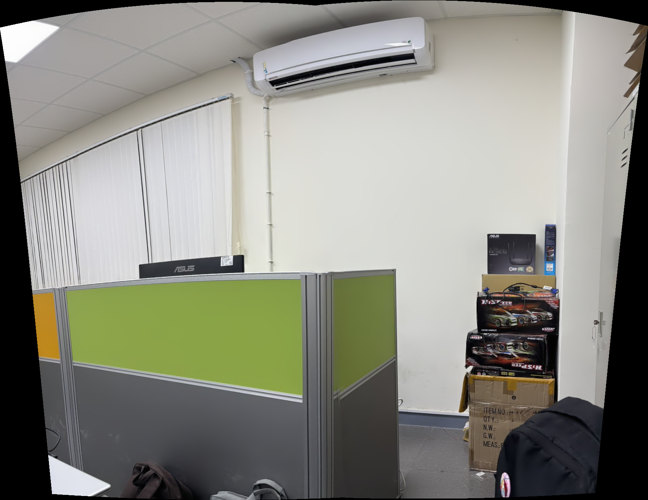

比較圖 （原尺寸 1995 × 778）


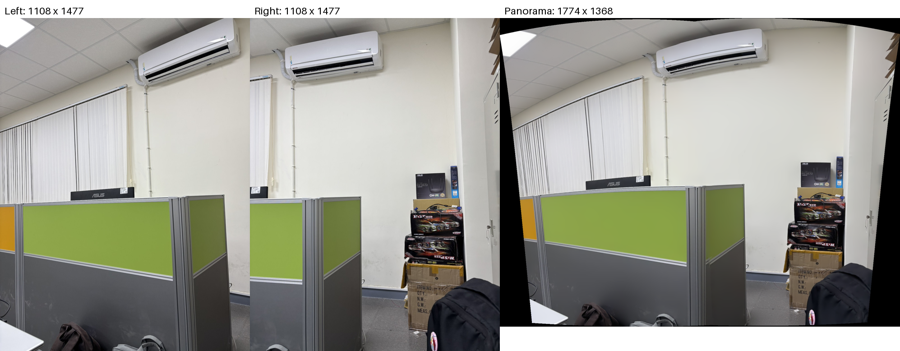

1 read_skill panorama-workflow 請填這個選擇的簡短依據 成功 此 Skill 的內容已交回模型，供下一輪規劃。
2 call_function get_local_photos 需要先獲取本地相片以進行全景拼接。 成功 下一輪將附上照片，模型可使用回傳的真實 ID。
3 call_function stitch_images 進行拼接以生成全景圖 成功 下一輪可用回傳的全景 ID 存檔。
4 call_function save_image 將拼接完成的全景存檔為 'panorama.png' 成功 可讀的全景路徑將與左、右原圖一同作為比較圖輸入。
5 read_skill image-comparison-report  成功 此 Skill 的內容已交回模型，供下一輪規劃。
6 inspect_functions  檢查三圖排版與尺寸標籤能力 成功 能力檢查結果已交回模型，模型可自行選擇撰寫並執行程式。


### 自行撰寫程式碼｜第 7 輪

[開啟實際生成的 Python](result/quiz3/agent/run_a68e6eec5a/comparison_r07.py)

7 write_and_run_python  需要自寫程式以實現三圖排版和原始尺寸標籤的功能 成功 腳本執行與 PNG 尺寸標籤驗收結果已交回模型。
8 finish  兩張 PNG 已驗證 成功 兩個成果皆已驗證，本次結束。


[完整 ReAct 紀錄](result/quiz3/agent/run_a68e6eec5a/react.json)

In [12]:
from IPython.display import Markdown, display
from other_code.quiz2 import ROOT, show_preview
from PIL import Image

for title, filename in (
    ("全景", q3_result["panorama"]),
    ("比較圖", (q3_result["comparison"] or {}).get("path")),
):
    if filename:
        with Image.open(ROOT / filename) as image:
            show_preview(title, image)
for row in q3_result["rounds"]:
    if row["action"] == "write_and_run_python" and row["observation"].get("ok"):
        script_path = row["observation"]["script"]
        display(Markdown(f"### 自行撰寫程式碼｜第 {row['round']} 輪\n\n[開啟實際生成的 Python]({script_path})"))
    observation = row["observation"]
    print(row["round"], row["action"], row["arguments"].get("name", ""),
          row["decision_basis"], observation.get("error", "成功"), row["next_effect"])
display(Markdown(f"[完整 ReAct 紀錄]({q3_result['record']})"))